In [1]:
import scomv
import stlearn as st
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
import pandas as pd
import numpy as np
import anndata
import scanpy as sc

/Users/nomura/miniconda3/envs/scomv-pip-2/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


/Users/nomura/miniconda3/envs/scomv-pip-2/lib/python3.11/site-packages/stlearn/tl/cci/het.py:206: NumbaDeprecationWarning: The keyword argument 'nopython=False' was supplied. From Numba 0.59.0 the default is being changed to True and use of 'nopython=False' will raise a warning as the argument will have no effect. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @jit(parallel=True, nopython=False)


In [2]:
# Download tutorial dataset
#!mkdir tutorial_data
#!mkdir tutorial_data/xenium_data
#!wget -P tutorial_data/xenium_data/ https://cf.10xgenomics.com/samples/xenium/preview/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_feature_matrix.h5
#!wget -P tutorial_data/xenium_data/ https://cf.10xgenomics.com/samples/xenium/preview/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_cells.csv.gz

In [3]:
import scomv
import stlearn as st
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from adjustText import adjust_text

adata = st.ReadXenium(
    feature_cell_matrix_file="../tutorial_data/xenium_data/cell_feature_matrix.h5",
    cell_summary_file="../tutorial_data/xenium_data/cells.csv.gz",
    library_id="example data",
    image_path=None,
    scale=1,
    spot_diameter_fullres=10,
)

sc.pp.filter_genes(adata, min_cells=300)

N_COL = int((adata.obs.imagecol.max() - adata.obs.imagecol.min()) / 10)
N_ROW = int((adata.obs.imagerow.max() - adata.obs.imagerow.min()) / 10)
grid = st.tl.cci.grid(adata, n_row=N_ROW, n_col=N_COL, n_cpus=10, verbose=False)

from scomv.preparation.skny_calc_distance import calculate_distance

grid = calculate_distance(grid, pos_marker_ls=["CDH1", "EPCAM"])

sc.pp.filter_cells(adata, min_genes=10)
print(adata)

[calculate_distance] N_ROW=547, N_COL=752, positive cells in grid=100012/411344


AnnData object with n_obs × n_vars = 163565 × 312
    obs: 'imagecol', 'imagerow', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'spatial'
    obsm: 'spatial'


In [4]:
from scomv.preparation.skny_calc_distance import calculate_distance

In [5]:
## apply SKNY
grid = calculate_distance(
    grid, pos_marker_ls=['CDH1',"EPCAM"],
)

[calculate_distance] N_ROW=547, N_COL=752, positive cells in grid=100012/411344


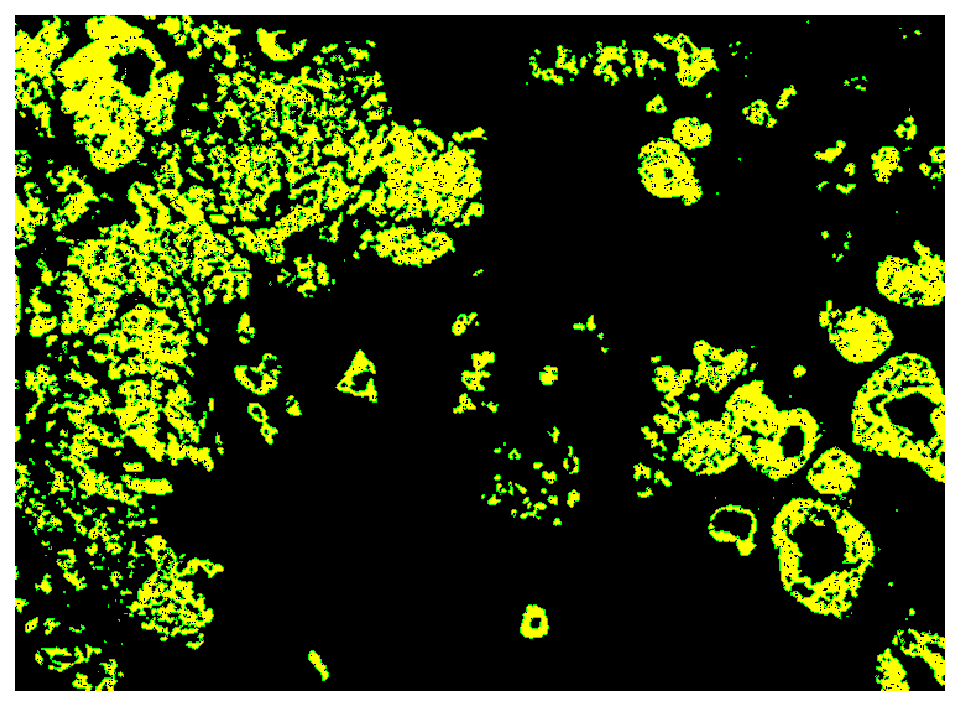

In [6]:
# Figure 2B
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
ax.imshow(cv2.cvtColor(grid.uns["marker_median_delineation"], cv2.COLOR_BGR2RGB),
          interpolation="nearest")
ax.axis("off")
plt.show()

In [7]:
import plotly.express as px
import plotly.io as pio
import cv2
import numpy as np

# Convert BGR (OpenCV) image to RGB for Plotly display
img = cv2.cvtColor(grid.uns["marker_median_delineation"], cv2.COLOR_BGR2RGB)

scale = 10  # spatial scaling factor

fig = px.imshow(img)

h, w = img.shape[:2]

# ---- Scale axis tick labels by a factor of 10 ----
step = 200
fig.update_xaxes(
    tickmode="array",
    tickvals=list(range(0, w, step)),
    ticktext=[str(v * scale) for v in range(0, w, step)]
)
fig.update_yaxes(
    tickmode="array",
    tickvals=list(range(0, h, step)),
    ticktext=[str(v * scale) for v in range(0, h, step)]
)

# ---- Create a full-resolution coordinate grid for hover display ----
# xx: scaled x-coordinates for each pixel (shape: h × w)
# yy: scaled y-coordinates for each pixel (shape: h × w)
xx = (np.arange(w)[None, :] * scale).repeat(h, axis=0)
yy = (np.arange(h)[:, None] * scale).repeat(w, axis=1)

# Stack into (h, w, 2) so hover can access scaled x and y
custom = np.dstack([xx, yy])

# ---- Override hover text to show scaled spatial coordinates ----
fig.update_traces(
    customdata=custom,
    hovertemplate="x: %{customdata[0]}<br>y: %{customdata[1]}<extra></extra>"
)

fig.update_layout(
    xaxis_title="x",
    yaxis_title="y",
    height=800
)

# Use the notebook-connected renderer for interactive display
pio.renderers.default = "notebook_connected"

fig.show()

# ↓↓ Zooming and cropping are supported interactively ↓↓

In [8]:
# distance band of every grid square (grid.obs["region_10"]), used by extract_roi
from scomv.preparation.choose_roi import add_distance_regions

grid = add_distance_regions(grid)

In [9]:
from scomv.preparation.choose_roi import extract_roi, contour_regions

In [10]:
# select ROI
roi = (2400, 3400, 2400, 3800)

subset_grid, filtered_shortest, xy_list = extract_roi(
    grid=grid,
    roi=roi,
    bin_size=10,
    region_col="region_10",
)

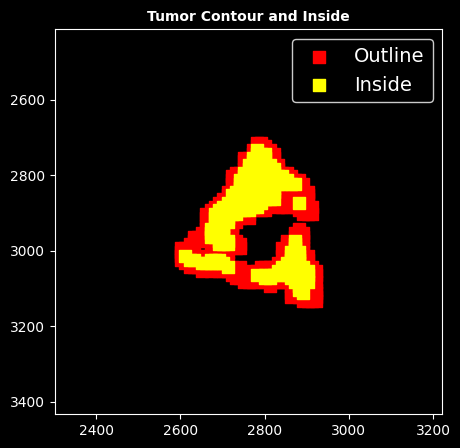

In [11]:
g_x_cont, g_y_cont, g_x_inside, g_y_inside = contour_regions(
    filtered_shortest, adata,
    min_x=0, max_x=4000, min_y=0, max_y=4000,
    show=True,
)

In [12]:
from scomv.preparation.scomv_calc_vector import compute_min_vectors_polar

outline_points = list(zip(g_x_cont, g_y_cont))
inside_points  = list(zip(g_x_inside, g_y_inside))

min_vector_df = compute_min_vectors_polar(
    xy_list=xy_list,
    outline_points=outline_points,
    inside_points=inside_points,
    invert_y=True,
    make_inside_negative=True,
)

In [13]:
# load cell_annotation file
file_path = "../tutorial_data/Cell_Barcode_Type_Matrices.xlsx"
xls = pd.ExcelFile(file_path)
cell_ann_df = pd.read_excel(file_path, sheet_name=xls.sheet_names[3])
print(cell_ann_df.head())

adata_obs = adata.obs
cell_ann_df.index = cell_ann_df.index + 1
adata_obs = adata_obs[["imagecol", "imagerow"]]
adata_obs.index = adata_obs.index.astype(int)


cell_df = pd.concat([adata_obs, cell_ann_df], axis=1)
cell_df = cell_df[["imagecol", "imagerow", "Cluster"]]
cell_df["Cluster"].unique()
#cell_df.to_csv("cell_annotation_df.csv")

   Barcode         Cluster
0        1          DCIS_2
1        2          DCIS_2
2        3       Unlabeled
3        4  Invasive_Tumor
4        5          DCIS_2


array(['DCIS_2', 'Macrophages_1', 'Unlabeled', 'Invasive_Tumor',
       'Stromal', 'DCIS_1', 'Myoepi_ACTA2+', 'CD8+_T_Cells',
       'Endothelial', 'Prolif_Invasive_Tumor', 'T_Cell_&_Tumor_Hybrid',
       'Mast_Cells', 'CD4+_T_Cells', 'B_Cells', 'Macrophages_2',
       'Stromal_&_T_Cell_Hybrid', 'Perivascular-Like', 'LAMP3+_DCs',
       'IRF7+_DCs', 'Myoepi_KRT15+'], dtype=object)

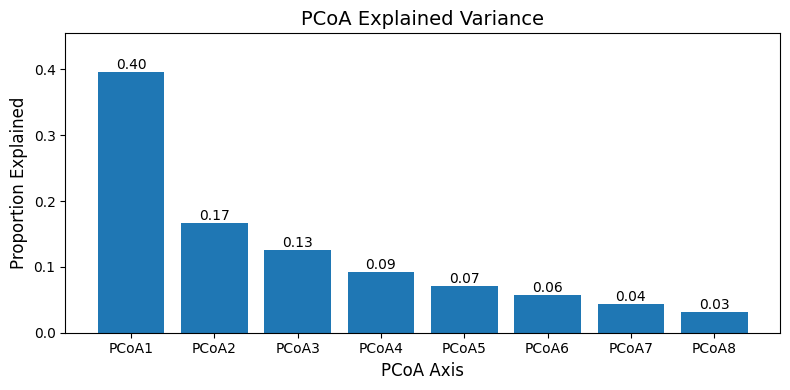

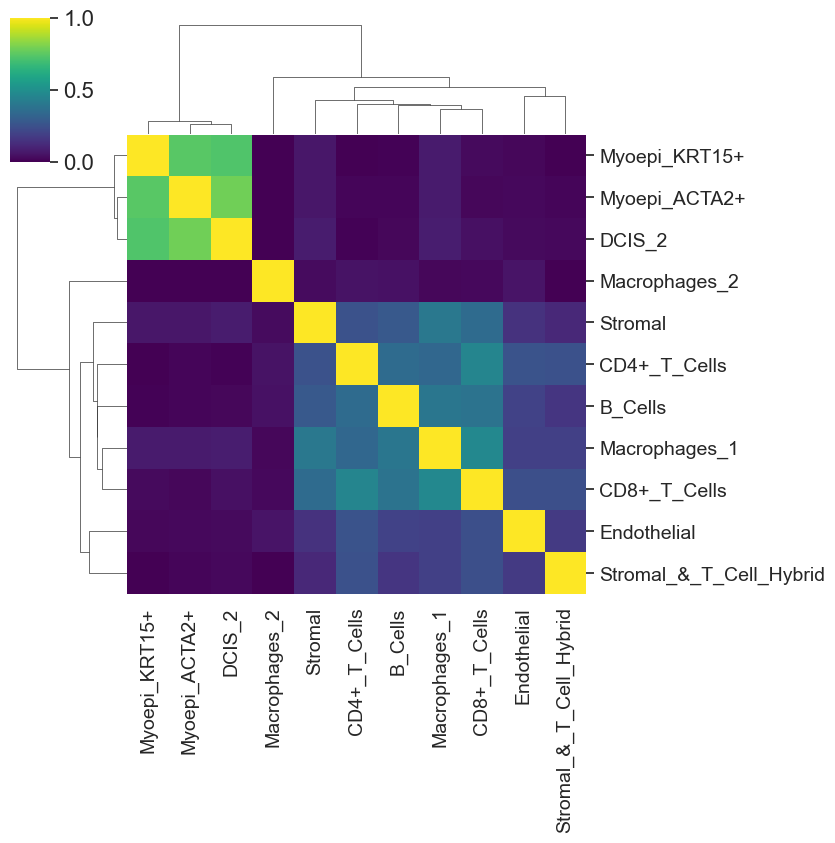

In [14]:
from scomv.cell_pipeline import CellPolarPipeline

# Initialize the pipeline with cell-level data and precomputed minimum-distance vectors
cell_pipe = CellPolarPipeline(
    cell_df=cell_df,
    min_vector_df=min_vector_df,
    grid=grid,  # place cells in grid squares with the grid's own edges
)

# Run the pipeline for a specified ROI (xmin, xmax, ymin, ymax)
# Disable histogram plotting during the run
cell_out = cell_pipe.run(
    roi=(2400, 3400, 2400, 3800),
    plot_hist=False
)

# Distance matrix between cells based on polar-vector representations
dist = cell_pipe.dist_df

# Plot explained variance of PCoA components
cell_pipe.plot_explained_variance(n_components=8)

# Plot a heatmap of similarities (displayed as 1 - distance)
cell_pipe.heatmap(font_size=14, figsize=(8, 8), cbar_fontsize=16)  # colour-bar labels 5 pt larger (default 11)


In [15]:
import math
from scomv.cell import compute_cluster_polar_distributions
from scomv.polar_plot import plot_polar_heatmap

RADIUS_BINS = np.arange(-100, 310, 10)  # -100 µm (inside) to 300 µm (outside)
ANGLE_BINS = np.arange(-180, 181, 30)
from matplotlib.ticker import FuncFormatter
# radius tick labels: unit on the outermost one only ("300 µm")
R_FMT = FuncFormatter(lambda v, _: (f"{v:g} µm" if v == 300 else f"{v:g}").replace("-", "\u2212"))
CLIM_RATIO = 0.5  # colour scale tops out at 50% of each cluster's maximum, as in the rectangular version

# histograms only (plot=False); the function still draws into a scratch figure, so close it
_, clusters, counts_by_cluster = compute_cluster_polar_distributions(
    cell_out["cell_df_filtered"], min_vector_df,
    radius_bins=RADIUS_BINS, angle_bins_deg=ANGLE_BINS, plot=False,
)
plt.close("all")
n_cells = cell_out["cell_df_filtered"]["Cluster"].value_counts()

# one circular (polar) map per cell type
n_cols = 3
n_rows = math.ceil(len(clusters) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(9.5 * n_cols, 9.5 * n_rows), dpi=300,
                         subplot_kw={"projection": "polar"}, squeeze=False)
for ax, cl in zip(axes.flat, clusters):
    A = counts_by_cluster[cl]
    plot_polar_heatmap(
        A, RADIUS_BINS, ANGLE_BINS, ax=ax,
        vmin=0, vmax=A.max() * CLIM_RATIO if A.max() > 0 else None,
        radius_ticks=[-100, 0, 100, 200, 300],
        hole_frac=0.15,
        boundary_kwargs=dict(color="white", lw=3, ls="--"),  # distance 0 = tumor boundary
        cbar_label="Density", fontsize=25,
        radius_label_angle=75,  # keep the radius labels clear of the 90° label
    )
    ax.set_title(f"{cl} (n = {n_cells[cl]})", fontsize=32, weight="bold", pad=50)
    ax.yaxis.set_major_formatter(R_FMT)
for ax in axes.flat[len(clusters):]:
    ax.set_visible(False)
fig.tight_layout(w_pad=4)  # room for the 180° labels next to the colour bars
plt.show()


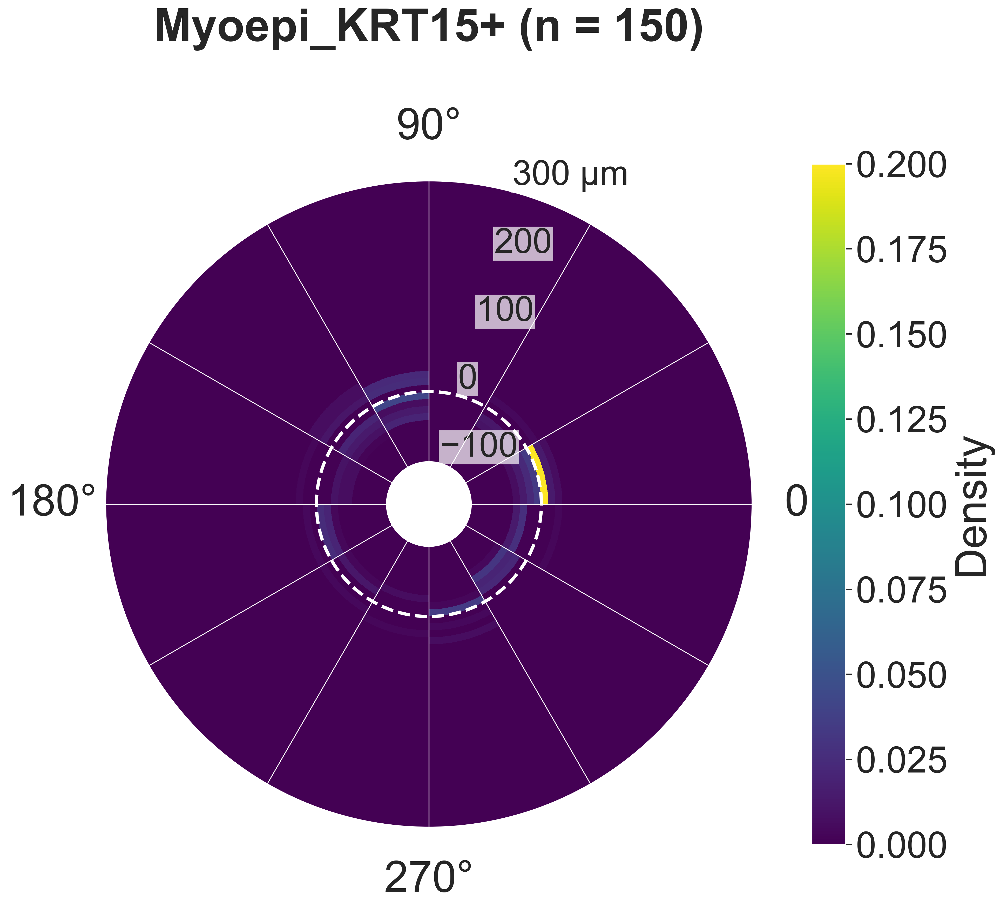

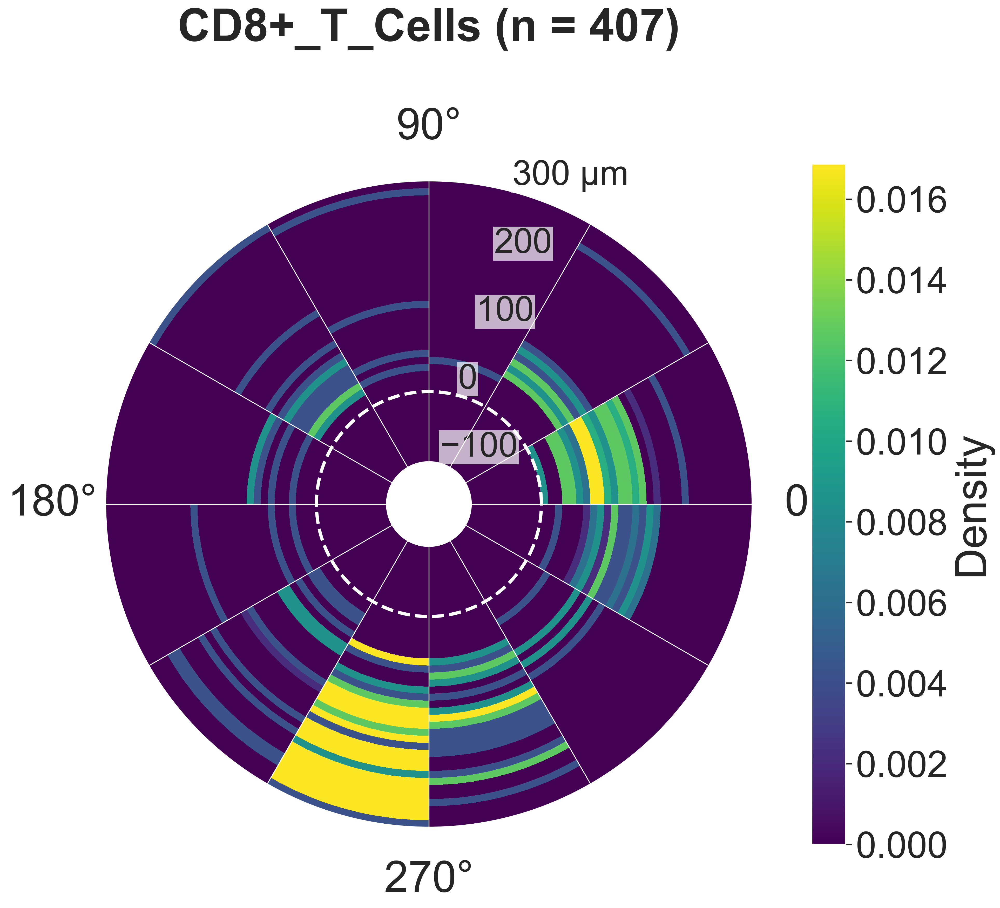

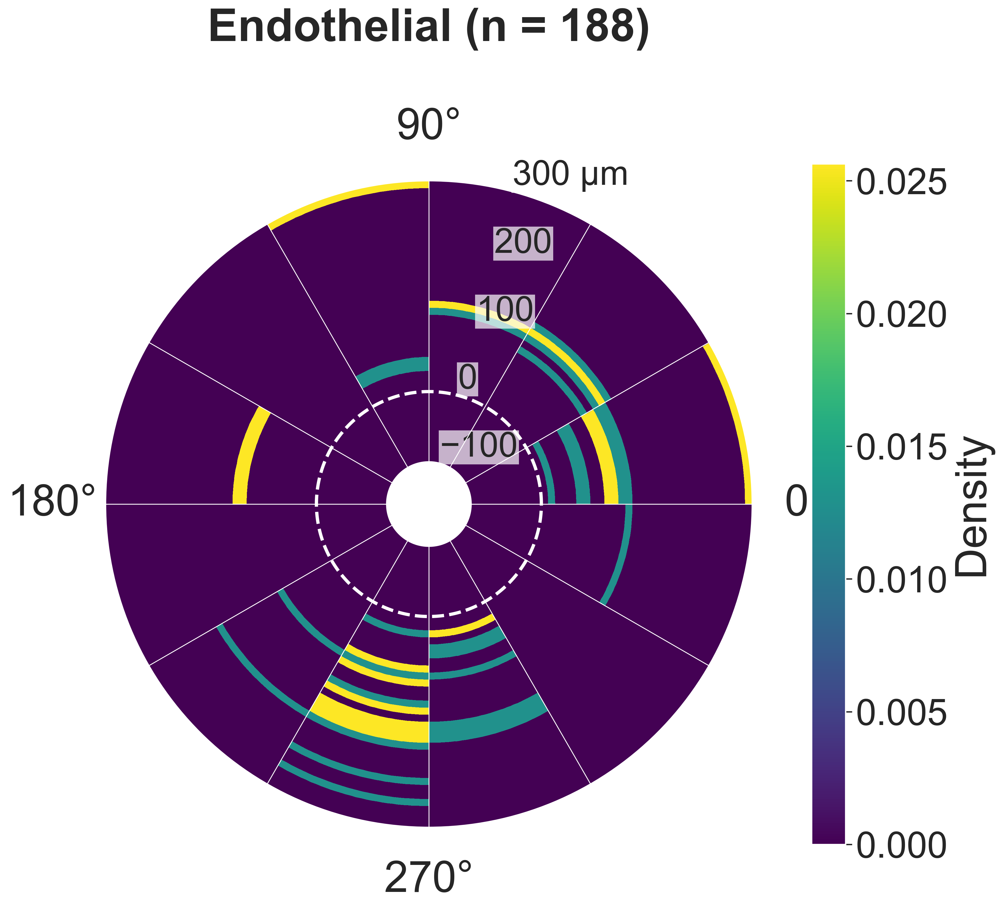

In [16]:
# Individual polar maps for selected cell types (same settings as above; text 15 pt larger, title 42 pt)
SHOW_TYPES = ["Myoepi_KRT15+", "CD8+_T_Cells", "Endothelial"]

for cl in SHOW_TYPES:
    A = counts_by_cluster[cl]
    fig, ax = plt.subplots(figsize=(13, 12), dpi=300, subplot_kw={"projection": "polar"})
    plot_polar_heatmap(
        A, RADIUS_BINS, ANGLE_BINS, ax=ax,
        vmin=0, vmax=A.max() * CLIM_RATIO if A.max() > 0 else None,
        radius_ticks=[-100, 0, 100, 200, 300],
        hole_frac=0.15,
        boundary_kwargs=dict(color="white", lw=3, ls="--"),
        cbar_label="Density", fontsize=40,
        radius_label_angle=75,
    )
    ax.set_title(f"{cl} (n = {n_cells[cl]})", fontsize=42, weight="bold", pad=62)
    ax.yaxis.set_major_formatter(R_FMT)  # "300 µm"
    fig.tight_layout()
    plt.show()


/Users/nomura/miniconda3/envs/scomv-pip-2/lib/python3.11/site-packages/anndata/_core/anndata.py:859: UserWarning:


AnnData expects .obs.index to contain strings, but got values like:
    [1, 2, 5, 8, 9]

    Inferred to be: integer




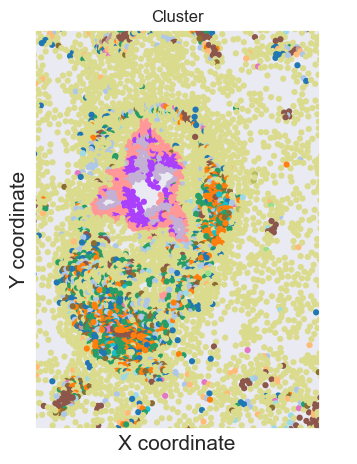

In [17]:
adata_2 = anndata.AnnData(X=np.zeros((len(cell_df), 0)))  # Dummy X
adata_2.obs = cell_df.copy()

# Store the coordinates used as the basis in adata.obsm
adata_2.obsm["spatial"] = cell_df[["imagecol", "imagerow"]].to_numpy()

# draw
sc.pl.embedding(
    adata_2,
    basis="spatial",
    color="Cluster",
    size=80,
    legend_loc=None,
    frameon=True,
    show=False,
)

ax = plt.gca()
ax.set_xlabel("X coordinate", fontsize=15)
ax.set_ylabel("Y coordinate", fontsize=15)
ax.tick_params(axis="both", labelsize=13)

# limit the range
ax.set_xlim(2400, 3400)
ax.set_ylim(2400, 3800)

# Align to the image coordinate system
ax.invert_yaxis()
ax.set_aspect("equal", adjustable="box")

legend = ax.legend(
    *ax.get_legend_handles_labels(),
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=12
)
plt.tight_layout()
plt.show()


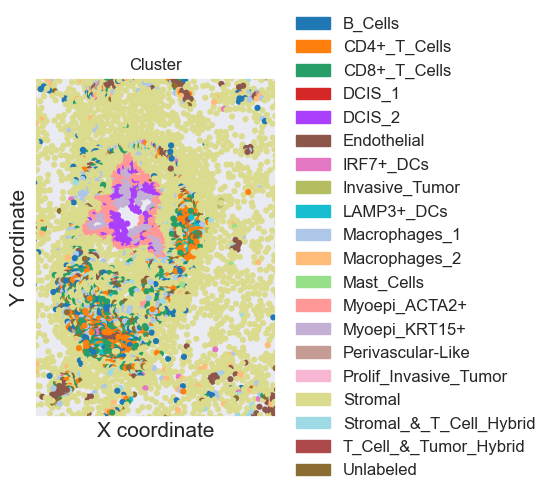

In [18]:
sc.pl.embedding(
    adata_2,
    basis="spatial",
    color="Cluster",
    size=80,
    legend_loc="none",
    frameon=True,
    show=False,
)

ax = plt.gca()
ax.set_xlabel("X coordinate", fontsize=15)
ax.set_ylabel("Y coordinate", fontsize=15)
ax.tick_params(axis="both", labelsize=13)
ax.set_xlim(2400, 3400)
ax.set_ylim(2400, 3800)
ax.invert_yaxis()
ax.set_aspect("equal", adjustable="box")

# Retrieve category names and colors stored in adata
cats = adata_2.obs["Cluster"].astype("category").cat.categories
colors = adata_2.uns.get("Cluster_colors")

handles = [mpatches.Patch(color=c, label=str(cat)) for c, cat in zip(colors, cats)]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=12)

plt.subplots_adjust(right=0.80)
plt.tight_layout()
plt.show()


/Users/nomura/miniconda3/envs/scomv-pip-2/lib/python3.11/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning:

Transforming to str index.

/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:7: FutureWarning:

The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.

/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

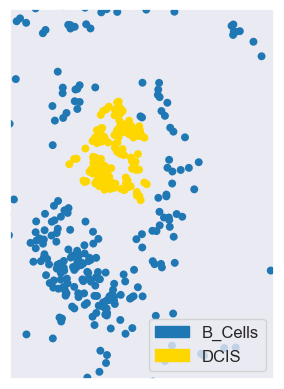

Figure: B_Cells + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

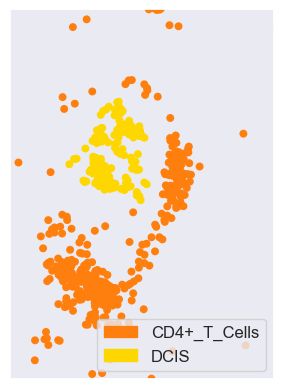

Figure: CD4+_T_Cells + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

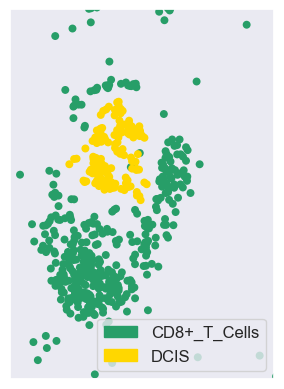

Figure: CD8+_T_Cells + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

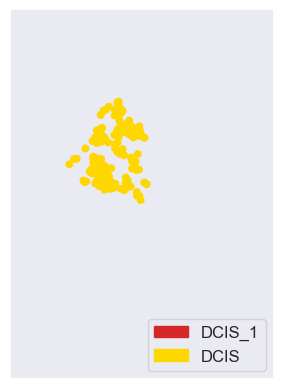

Figure: DCIS_1 + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

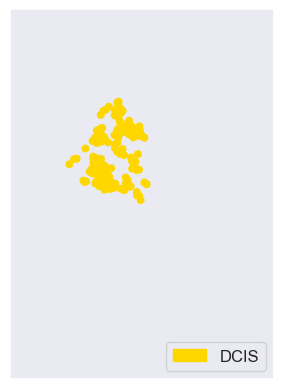

Figure: DCIS + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

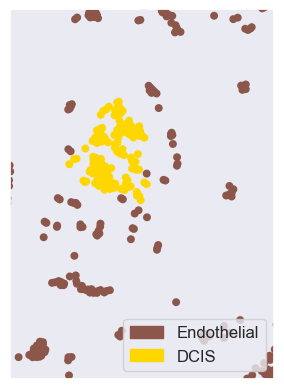

Figure: Endothelial + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

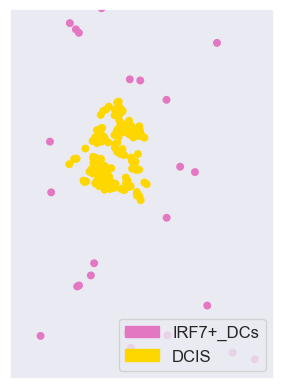

Figure: IRF7+_DCs + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

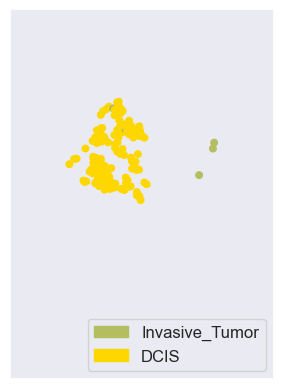

Figure: Invasive_Tumor + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

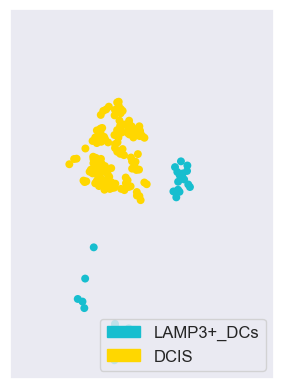

Figure: LAMP3+_DCs + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

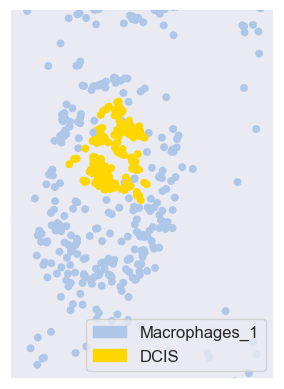

Figure: Macrophages_1 + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

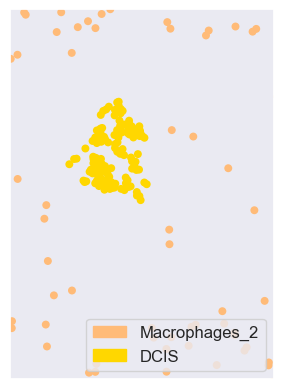

Figure: Macrophages_2 + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

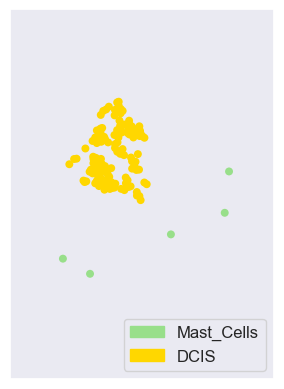

Figure: Mast_Cells + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

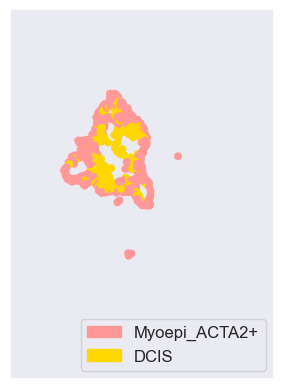

Figure: Myoepi_ACTA2+ + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

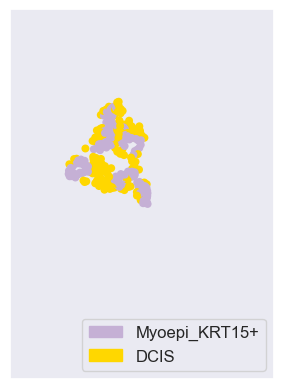

Figure: Myoepi_KRT15+ + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

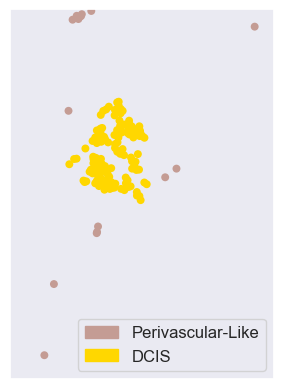

Figure: Perivascular-Like + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

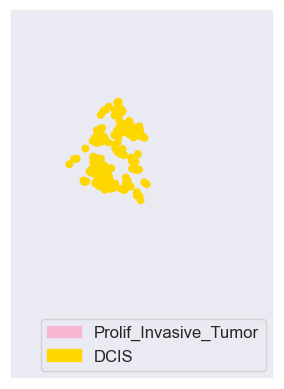

Figure: Prolif_Invasive_Tumor + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

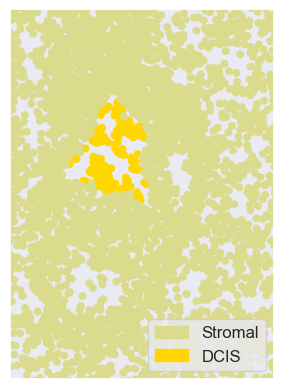

Figure: Stromal + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

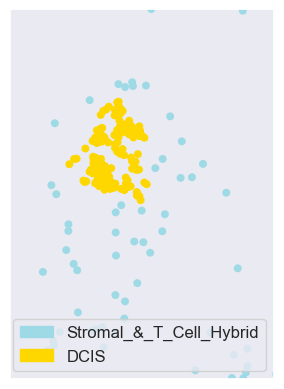

Figure: Stromal_&_T_Cell_Hybrid + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

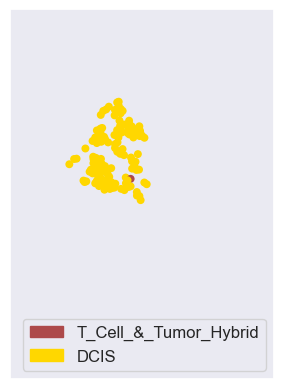

Figure: T_Cell_&_Tumor_Hybrid + DCIS


/var/folders/h5/02yhm93d3kn1__fczqjdr9cw0000gp/T/ipykernel_86959/3277719802.py:31: FutureWarning:

Use `squidpy.pl.spatial_scatter` instead.



<Figure size 1000x1000 with 0 Axes>

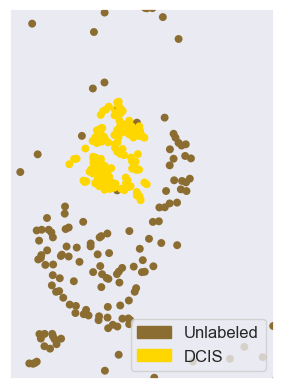

Figure: Unlabeled + DCIS


In [19]:
# List of cluster categories
clusters = adata_2.obs["Cluster"].astype("category").cat.categories

# Create a copy of adata and rename DCIS_2 → DCIS
adata_2_renamed = adata_2.copy()
adata_2_renamed.obs["Cluster"] = (
    adata_2_renamed.obs["Cluster"].replace({"DCIS_2": "DCIS"}).astype("category")
)

# Color settings: DCIS in yellow, others keep original colors
orig_cats = adata_2.obs["Cluster"].astype("category").cat.categories
orig_colors = adata_2.uns["Cluster_colors"]
color_dict = dict(zip(orig_cats, orig_colors))

cats = list(adata_2_renamed.obs["Cluster"].cat.categories)
colors = []
for c in cats:
    if c == "DCIS":
        colors.append("#FFD700")
    else:
        orig_name = "DCIS_2" if c == "DCIS" and "DCIS_2" in orig_cats else c
        colors.append(color_dict.get(orig_name, "gray"))

adata_2_renamed.uns["Cluster_colors"] = colors

# Plot "DCIS + each cluster" separately
for cluster in clusters:
    cluster_name = "DCIS" if cluster == "DCIS_2" else cluster

    plt.figure(figsize=(10, 10))
    sc.pl.spatial(
        adata_2_renamed[adata_2_renamed.obs["Cluster"].isin([cluster_name, "DCIS"])],
        img_key="hires",
        color="Cluster",
        size=1.5,
        spot_size=20,
        legend_loc="lower right",
        frameon=True,
        show=False,
    )

    ax = plt.gca()

    # Remove axis titles and labels
    ax.set_title("")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="both", labelsize=11)

    # Manually construct legend for selected clusters
    handle_map = {cat: col for cat, col in zip(cats, adata_2_renamed.uns["Cluster_colors"])}
    show_labels = [cluster_name, "DCIS"]
    show_labels = list(dict.fromkeys(show_labels))  # Remove duplicates for DCIS plots
    handles = [
        mpatches.Patch(color=handle_map[label], label=label)
        for label in show_labels
    ]
    ax.legend(handles=handles, loc="lower right", frameon=True, fontsize=12)

    ax.set_axis_on()

    # Set ROI limits
    ax.set_xlim(2400, 3400)
    # ax.set_xticks(range(2400, 3401, 200))
    ax.set_ylim(2400, 3800)
    # ax.set_yticks(range(2400, 3801, 200))

    # Align to image coordinate system
    ax.invert_yaxis()
    ax.set_aspect("equal", adjustable="box")

    # Save figure (optional)
    # plt.savefig(f"{root}/cell_location_fig/{cluster_name}_no_tick.png", dpi=300)

    plt.show()
    print(f"Figure: {cluster_name} + DCIS")
